# Part 1
Understanding the dataset

1.1. [1 point] Why are you interested in this dataset?

As students, we found it interesting to be able to analyze the impacts of studying and reviewing habits to see how those factors can be modeled to predict a student’s level of understanding. Using this data set for this assignment will not only help us understand the concepts of PCA, k-mean and DBSCAN, but also give us good insights to how study habits may impact our acidemic performance.

1.2. [1 point] How many numerical attributes and categorical attributes are there in the dataset?

Numerical attributes: 5 (STG, SCG, STR, LPR, PEG)
Categorical attributes: 1 (UNS)

1.3. [2 point] Are there any missing values in numerical attributes? If so, how are you going to
handle them? (Are you going to remove all data instances with missing values?) Will all
attributes with missing values be removed? Will missing values be imputed? If so, how?

There are no missing values.

1.4. Before doing any analysis, answer the following questions.
1.4.1. [1 point] Why do you think clusters will be present in this dataset?


Clusters will be present because students tend to have similar patterns in their study habits and performance. We expect that students with similar combinations of studying, practice, and exam scores will group together, forming natural clusters in the data.

1.4.2. [1 point] Why might finding clusters in this dataset be helpful? (How might this help us to
understand or analyze data?)


Finding clusters is helpful because it groups students with similar study behaviors and performance together. For example, it can show groups of students who consistently perform well with strong study habits, and students who struggle despite studying. This helps break the data into meaningful categories that are easier to analyze and interpret.

1.4.3. [1 point] How many clusters do you expect to see in this dataset? You can provide a range
of values for this question.   (Ex: 2-5). Why do you expect to see this number of clusters in
this dataset?


About 3–4 clusters.

Low performing / Low study students
Medium performing students with average study habits
High performing / High study students
Possibly a mixed or borderline group where study habits and performance don’t clearly match

1.4.4. [2 point] Do you expect to see clusters of similar size? Why or why not?

We do not expect clusters to be the same size because the data is not evenly distributed. Some types of students (like average study habits and average scores) are likely to appear more often than others, so those groups will form larger clusters, while less common patterns will form smaller ones.

# Part 2
Write the following functions in Python. You may use the scikit-learn or other packages to
check the correctness of your implementation, but you may not use existing clustering algorithm
implementations in your code. Provide test cases for your functions. You can use existing data
structures and basic helper functions numpy, pandas, etc

In [1]:
import numpy as np

2.1. [10 points] A function that implements k-means clustering algorithm. This function should take
a data matrix, a number of clusters k, and a convergence parameter 𝝐 (𝒆𝒑𝒔𝒊𝒍𝒐𝒏), as inputs,
and return the representatives (means) as well as the clusters found using k-means. If the
distance is the same between a point and more than one representative (mean), then assign
the point to the mean corresponding to the cluster with the lowest index.


In [2]:
def kmeans(X, k, epsilon):
    indices = np.random.choice(len(X), k, replace=False)
    centroids = X[indices]

    while True:
        # assign each point to nearest centroid
        labels = np.zeros(len(X), dtype=int)
        for i, point in enumerate(X):
            distances = [np.linalg.norm(point - centroid) for centroid in centroids]
            labels[i] = np.argmin(distances)

        # recompute centroids
        new_centroids = np.zeros_like(centroids)
        for i in range(k):
            points_in_cluster = X[labels == i]
            if len(points_in_cluster) > 0:
                new_centroids[i] = np.mean(points_in_cluster, axis=0)
            else:
                new_centroids[i] = centroids[i]

        # check convergence
        if np.max(np.abs(new_centroids - centroids)) < epsilon:
            break

        centroids = new_centroids

    return centroids, labels


# Two separated clusters
X_test = np.array([
    [1, 1], [1.5, 1], [1, 1.5],   # cluster A
    [9, 9], [9.5, 9], [9, 9.5]    # cluster B
])

centroids, labels = kmeans(X_test, k=2, epsilon=0.0001)
print("Labels:", labels)   # should be [0,0,0,1,1,1] or [1,1,1,0,0,0]
print("Centroids:", centroids)

Labels: [0 0 0 1 1 1]
Centroids: [[1.16666667 1.16666667]
 [9.16666667 9.16666667]]


2.2. [10 points] A function that implements DBSCAN clustering algorithm. The function should take
a data matrix and the parameters, minpts and 𝝐 (epsilon) as inputs, and return the clusters
found using DBSCAN, where each data point is labeled as either a noise point, a border point,
or a core point.


In [3]:
def dbscan(X, minpts, epsilon):
    labels = np.full(len(X), -1)
    point_types = np.full(len(X), "noise", dtype=object)
    cluster_id = 0

    visited = set()
    for i in range(len(X)):
        if i in visited:
            continue
        else:
            visited.add(i)

        # find all neighbors within epsilon distance
        neighbors = get_neighbors(X, i, epsilon)
        if len(neighbors) < minpts:
            # not enough neighbors, mark as noise
            labels[i] = -1
        else:
            # enough neighbors, start a new cluster and expand it
            expand_cluster(X, labels, point_types, neighbors, i, cluster_id, minpts, epsilon, visited)
            cluster_id += 1


    return labels, point_types

def get_neighbors(X, point_id, epsilon):
    # collect all points within epsilon distance of point_id
    neighbors = []
    for i, point in enumerate(X):
        if np.linalg.norm(X[point_id] - point) < epsilon:
            neighbors.append(i)
    return neighbors

def expand_cluster(X, labels, point_types, neighbors, i, cluster_id, minpts, epsilon, visited):
    # assign core point to cluster
    labels[i] = cluster_id
    point_types[i] = "core"

    queue = list(neighbors)

    while queue:
        j = queue.pop(0)

        if j not in visited:
            visited.add(j)
            # check if j is also a core point
            j_neighbors = get_neighbors(X, j, epsilon)

            if len(j_neighbors) >= minpts:
                # j is a core point, expand cluster through its neighbors
                point_types[j] = "core"
                queue += [n for n in j_neighbors if n not in visited]
            else:
                # j is reachable but can't expand further
                point_types[j] = "border"

        # absorb point into current cluster if unassigned
        if labels[j] == -1:
            labels[j] = cluster_id

X_test = np.array([
    [1, 1], [1.2, 1], [1.1, 1.2],   # cluster A
    [8, 8], [8.2, 8], [8.1, 8.2],   # cluster B
    [50, 50]                          # noise
])

labels, point_types = dbscan(X_test, minpts=2, epsilon=0.5)
print("Labels:", labels)      # should be [0,0,0,1,1,1,-1]
print("Types:", point_types)  # cluster points = core/border, last = noise

Labels: [ 0  0  0  1  1  1 -1]
Types: ['core' 'core' 'core' 'core' 'core' 'core' 'noise']


2.3. [3 points] Extra Credit: A function that computes the precision of clustering. The function
should take a list of true cluster labels and a list of predicted cluster labels returned by a
clustering algorithm and return the precision of the clustering.

In [36]:
from collections import Counter

def clustering_precision(true_labels, predicted_labels):
    true_labels = np.array(true_labels)
    predicted_labels = np.array(predicted_labels)

    mask = predicted_labels != -1
    true_labels = true_labels[mask]
    predicted_labels = predicted_labels[mask]

    if len(predicted_labels) == 0:
        return 0
        
    cluster_map = {}
    for cluster in np.unique(predicted_labels):
        cluster_points = true_labels[predicted_labels == cluster]
        most_common = Counter(cluster_points).most_common(1)[0][0]
        cluster_map[cluster] = most_common

    correct = 0
    for t, p in zip(true_labels, predicted_labels):
        if cluster_map[p] == t:
            correct += 1

    return correct / len(true_labels)

# Part 3
 Analyze your data. Report the following, using tables or figures as appropriate. You may use
scikit-learn’s implementation of k-means and DBSCAN, but you are encouraged to first try using your
own implementations on real-world data

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("Data_User_Modeling.csv")
df.columns = df.columns.str.strip()

X = df[["STG", "SCG", "STR", "LPR", "PEG"]].values

y_true = df["UNS"].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

3.1. [5 points] First use sklearn’s PCA library to linearly transform the dataset into two dimensions.
Create a scatter plot of the dataset where x-axis corresponds to 1st principal component and yaxis corresponds to 2nd principal component. Does it look like there are clusters in the dataset
in these two dimensions? If so, how many clusters are there?

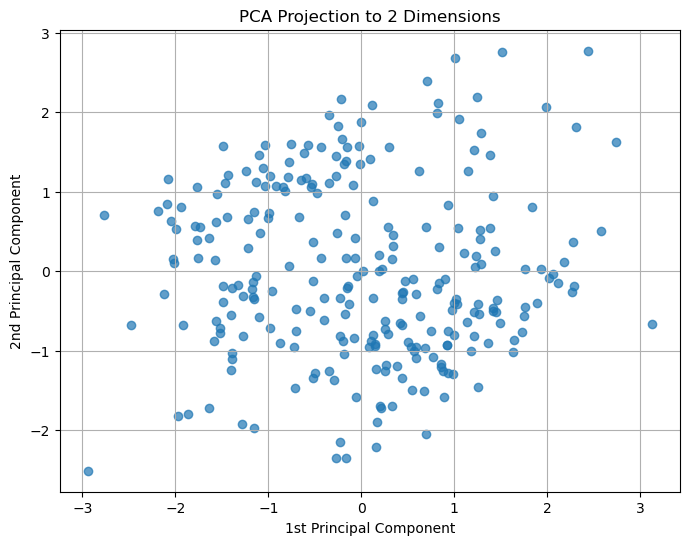

Explained variance ratio of PC1 and PC2: [0.27784814 0.23803464]
Total variance captured by first 2 PCs: 0.5158827764391205


In [27]:
pca_2 = PCA(n_components=2)
X_pca_2 = pca_2.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], alpha=0.7)
plt.xlabel("1st Principal Component")
plt.ylabel("2nd Principal Component")
plt.title("PCA Projection to 2 Dimensions")
plt.grid(True)
plt.show()

print("Explained variance ratio of PC1 and PC2:", pca_2.explained_variance_ratio_)
print("Total variance captured by first 2 PCs:", np.sum(pca_2.explained_variance_ratio_))

After applying PCA to reduce the dataset to two dimensions, the scatter plot shows that the data points are somewhat spread out with no clearly separated clusters. However, there are loose groupings visible, suggesting that some clustering structure exists in the data. Based on the distribution, it appears that there may be approximately 3 to 4 clusters, although they overlap significantly in the two-dimensional projection.

The first two principal components capture about 51.6% of the total variance, indicating that while they represent a significant portion of the data, some structure may still be present in higher dimensions.

3.2. [4 points] Use the sklearn’s PCA library without inputting the number of components to use.
Then create a plot where x-axis is the number of principal components and y-axis is the
fraction of variance captured by the first r principal components. Based on this plot, choose a
number of principal components to reduce the dimensionality of the data. Write down the
fraction of the variance captured by the chosen set of principal components.


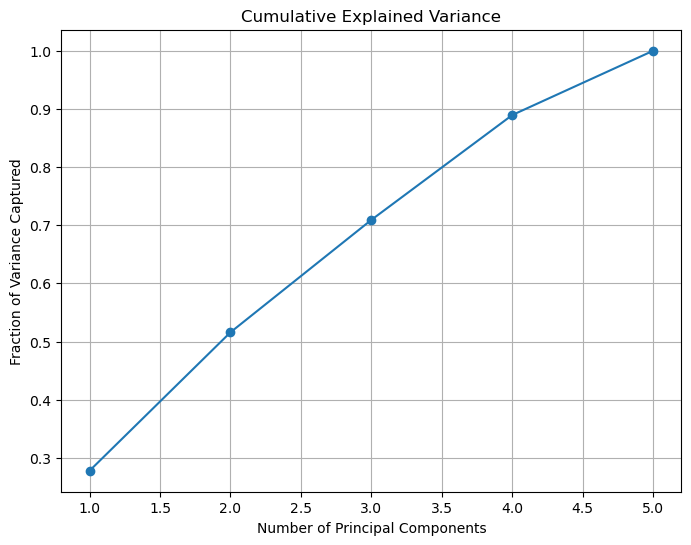

Explained variance: [0.27784814 0.23803464 0.19330586 0.18027546 0.11053591]
Cumulative variance: [0.27784814 0.51588278 0.70918863 0.88946409 1.        ]


In [28]:
pca = PCA()
pca.fit(X_scaled)

explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

plt.figure(figsize=(8, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
plt.xlabel("Number of Principal Components")
plt.ylabel("Fraction of Variance Captured")
plt.title("Cumulative Explained Variance")
plt.grid(True)
plt.show()

print("Explained variance:", explained_variance)
print("Cumulative variance:", cumulative_variance)

We applied PCA and plotted the cumulative explained variance. Based on the plot, we chose r = 4 principal components because they capture most of the variance while reducing dimensionality. The first four components capture about 88.95% of the total variance.

3.3. [6 points] For both original and reduced dimensionality data obtained in 3.2 do the following.
Run the k-means algorithm on a range of values for number of clusters k. Use at least 6
different k values for this. Plot the objective function value for each of the k values that you
used. Note that since you are doing this for original and dimensionality reduced datasets, you
need to create two plots. For original and dimensionality reduced datasets, what would be
good k-values based on the plots?


/lib/python3.13/site-packages/threadpoolctl.py:1123: RuntimeWarning: JsProxy.as_object_map() is deprecated. Use as_py_json() instead.
  for filepath in LDSO.loadedLibsByName.as_object_map():


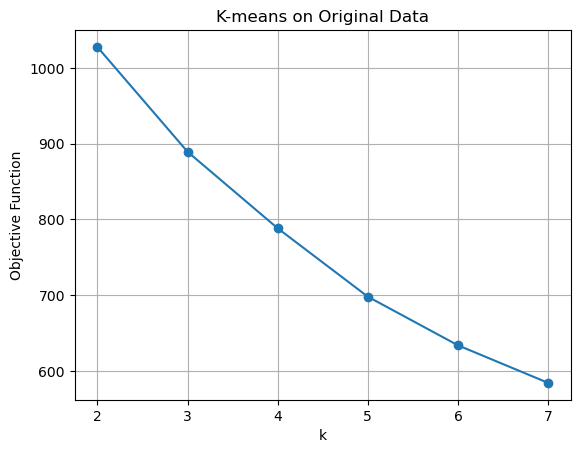

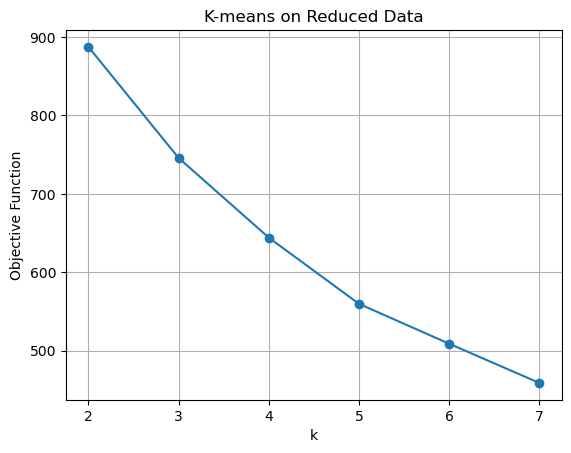

In [29]:
pca_r = PCA(n_components=4)
X_reduced = pca_r.fit_transform(X_scaled)

from sklearn.cluster import KMeans

def compute_objective(X, labels, centers):
    total = 0
    for i in range(len(X)):
        total += np.linalg.norm(X[i] - centers[labels[i]])**2
    return total

k_values = [2, 3, 4, 5, 6, 7]

original_obj = []
reduced_obj = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    obj = compute_objective(X_scaled, labels, kmeans.cluster_centers_)
    original_obj.append(obj)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=0, n_init=10)
    labels = kmeans.fit_predict(X_reduced)
    obj = compute_objective(X_reduced, labels, kmeans.cluster_centers_)
    reduced_obj.append(obj)

plt.figure()
plt.plot(k_values, original_obj, marker='o')
plt.xlabel("k")
plt.ylabel("Objective Function")
plt.title("K-means on Original Data")
plt.grid(True)
plt.show()

plt.figure()
plt.plot(k_values, reduced_obj, marker='o')
plt.xlabel("k")
plt.ylabel("Objective Function")
plt.title("K-means on Reduced Data")
plt.grid(True)
plt.show()

Both plots show a clear elbow around k = 3 to 4, suggesting that this range provides a good balance between minimizing the objective function and avoiding unnecessary clusters.

3.4. [6 points] For both original and reduced dimensionality data obtained in 3.2 do the following.
Run the DBSCAN algorithm with a range of values for the minpts and epsilon parameters to
find clusters in the datasets. First, you can keep the minpts fixed and vary the epsilon parameter, then you can keep the epsilon parameter fixed and vary the minpts parameter. Use
at least 6 different values for minpts and 6 different values for epsilon. Report the number of
clusters found for each minpts and epsilon pair.

In [32]:
from sklearn.cluster import DBSCAN

def count_clusters(labels):
    unique = set(labels)
    if -1 in unique:
        unique.remove(-1)
    return len(unique)

eps_values = [0.3, 0.5, 0.7, 0.9, 1.1, 1.3]
minpts_values = [3, 4, 5, 6, 7, 8]

fixed_minpts = 5
fixed_eps = 0.7

print("The following results show the number of clusters found for each combination of epsilon and minpts.\n")

print("ORIGINAL DATA\n")

print("Vary epsilon (minpts = 5):")
for eps in eps_values:
    model = DBSCAN(eps=eps, min_samples=fixed_minpts)
    labels = model.fit_predict(X_scaled)
    print("epsilon =", eps, "clusters =", count_clusters(labels))

print("\nVary minpts (epsilon = 0.7):")
for m in minpts_values:
    model = DBSCAN(eps=fixed_eps, min_samples=m)
    labels = model.fit_predict(X_scaled)
    print("minpts =", m, "clusters =", count_clusters(labels))

print("\nREDUCED DATA\n")

print("Vary epsilon (minpts = 5):")
for eps in eps_values:
    model = DBSCAN(eps=eps, min_samples=fixed_minpts)
    labels = model.fit_predict(X_reduced)
    print("epsilon =", eps, "clusters =", count_clusters(labels))

print("\nVary minpts (epsilon = 0.7):")
for m in minpts_values:
    model = DBSCAN(eps=fixed_eps, min_samples=m)
    labels = model.fit_predict(X_reduced)
    print("minpts =", m, "clusters =", count_clusters(labels))

The following results show the number of clusters found for each combination of epsilon and minpts.

ORIGINAL DATA

Vary epsilon (minpts = 5):
epsilon = 0.3 clusters = 0
epsilon = 0.5 clusters = 0
epsilon = 0.7 clusters = 2
epsilon = 0.9 clusters = 6
epsilon = 1.1 clusters = 3
epsilon = 1.3 clusters = 1

Vary minpts (epsilon = 0.7):
minpts = 3 clusters = 12
minpts = 4 clusters = 4
minpts = 5 clusters = 2
minpts = 6 clusters = 1
minpts = 7 clusters = 0
minpts = 8 clusters = 0

REDUCED DATA

Vary epsilon (minpts = 5):
epsilon = 0.3 clusters = 0
epsilon = 0.5 clusters = 2
epsilon = 0.7 clusters = 3
epsilon = 0.9 clusters = 3
epsilon = 1.1 clusters = 2
epsilon = 1.3 clusters = 1

Vary minpts (epsilon = 0.7):
minpts = 3 clusters = 13
minpts = 4 clusters = 5
minpts = 5 clusters = 3
minpts = 6 clusters = 4
minpts = 7 clusters = 3
minpts = 8 clusters = 2


3.5. [3 points] Extra credit: Create a plot of clustering precision for each value of k used in question
3.3, then create a plot of clustering precision for each value of epsilon used in question 3.4,
then create a plot of clustering precision for each value of minpts used in question 3.4. You
need to do this for both original and reduced dimensionality datasets. Overall, there should be
6 plots in total for this.

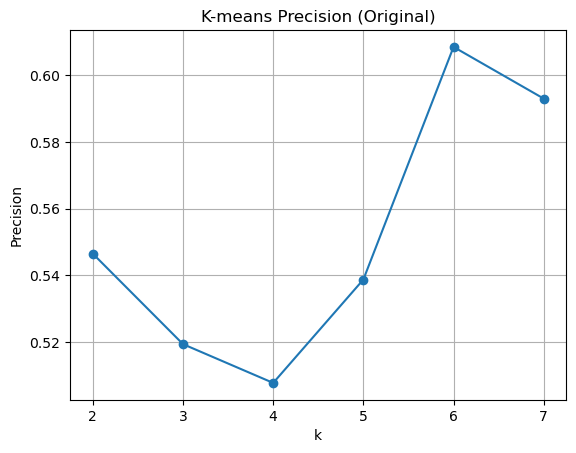

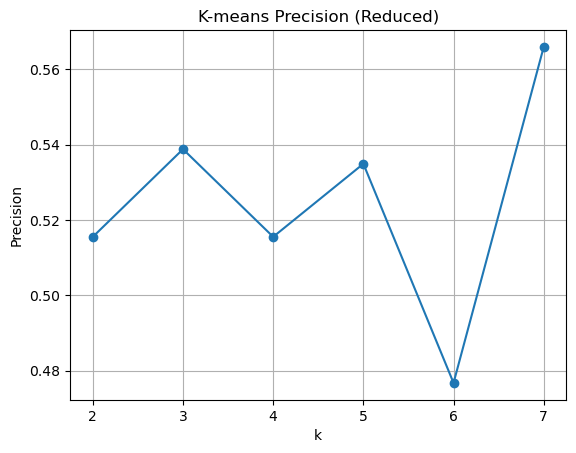

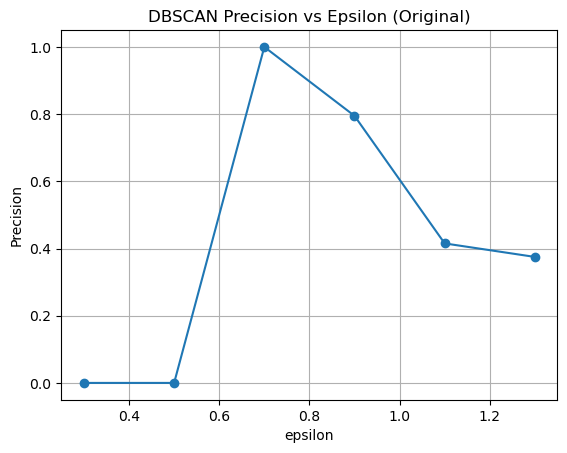

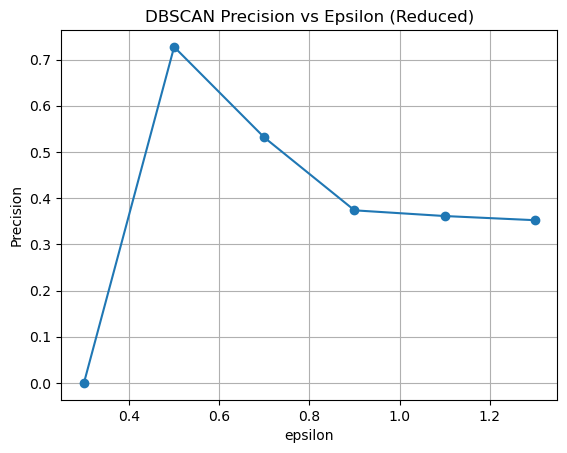

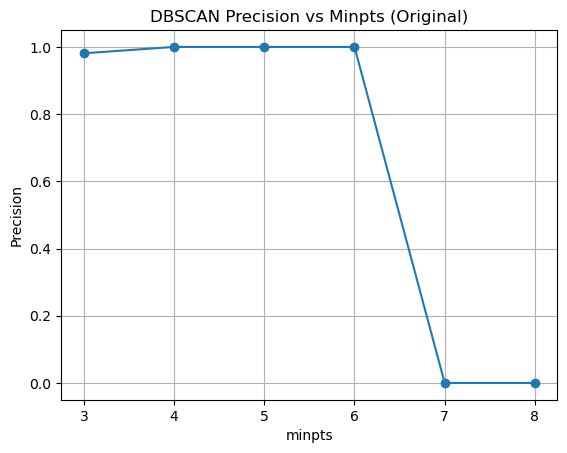

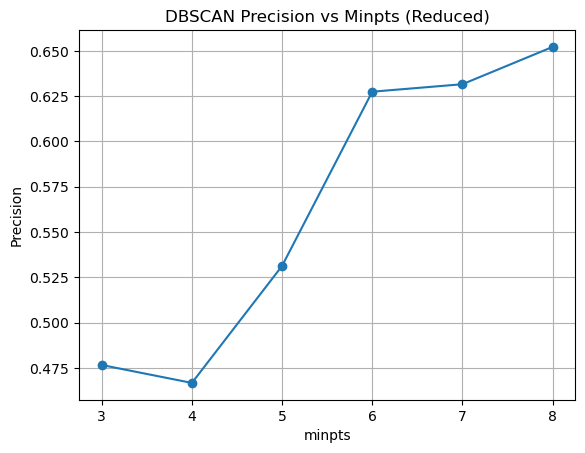

In [33]:
def clustering_precision(y_true, labels):
    y_true = np.array(y_true)
    labels = np.array(labels)

    mask = labels != -1
    y_true = y_true[mask]
    labels = labels[mask]

    if len(labels) == 0:
        return 0

    cluster_map = {}
    for c in np.unique(labels):
        vals = y_true[labels == c]
        most_common = Counter(vals).most_common(1)[0][0]
        cluster_map[c] = most_common

    correct = 0
    for t, l in zip(y_true, labels):
        if cluster_map[l] == t:
            correct += 1

    return correct / len(y_true)

k_values = [2, 3, 4, 5, 6, 7]

k_prec_orig = []
k_prec_red = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=0, n_init=10)
    labels = model.fit_predict(X_scaled)
    k_prec_orig.append(clustering_precision(y_true, labels))

    labels = model.fit_predict(X_reduced)
    k_prec_red.append(clustering_precision(y_true, labels))


plt.figure()
plt.plot(k_values, k_prec_orig, marker='o')
plt.title("K-means Precision (Original)")
plt.xlabel("k")
plt.ylabel("Precision")
plt.grid(True)
plt.show()

plt.figure()
plt.plot(k_values, k_prec_red, marker='o')
plt.title("K-means Precision (Reduced)")
plt.xlabel("k")
plt.ylabel("Precision")
plt.grid(True)
plt.show()

eps_values = [0.3, 0.5, 0.7, 0.9, 1.1, 1.3]
fixed_minpts = 5

eps_prec_orig = []
eps_prec_red = []

for eps in eps_values:
    model = DBSCAN(eps=eps, min_samples=fixed_minpts)

    labels = model.fit_predict(X_scaled)
    eps_prec_orig.append(clustering_precision(y_true, labels))

    labels = model.fit_predict(X_reduced)
    eps_prec_red.append(clustering_precision(y_true, labels))

plt.figure()
plt.plot(eps_values, eps_prec_orig, marker='o')
plt.title("DBSCAN Precision vs Epsilon (Original)")
plt.xlabel("epsilon")
plt.ylabel("Precision")
plt.grid(True)
plt.show()

plt.figure()
plt.plot(eps_values, eps_prec_red, marker='o')
plt.title("DBSCAN Precision vs Epsilon (Reduced)")
plt.xlabel("epsilon")
plt.ylabel("Precision")
plt.grid(True)
plt.show()

minpts_values = [3, 4, 5, 6, 7, 8]
fixed_eps = 0.7

minpts_prec_orig = []
minpts_prec_red = []

for m in minpts_values:
    model = DBSCAN(eps=fixed_eps, min_samples=m)

    labels = model.fit_predict(X_scaled)
    minpts_prec_orig.append(clustering_precision(y_true, labels))

    labels = model.fit_predict(X_reduced)
    minpts_prec_red.append(clustering_precision(y_true, labels))

plt.figure()
plt.plot(minpts_values, minpts_prec_orig, marker='o')
plt.title("DBSCAN Precision vs Minpts (Original)")
plt.xlabel("minpts")
plt.ylabel("Precision")
plt.grid(True)
plt.show()

plt.figure()
plt.plot(minpts_values, minpts_prec_red, marker='o')
plt.title("DBSCAN Precision vs Minpts (Reduced)")
plt.xlabel("minpts")
plt.ylabel("Precision")
plt.grid(True)
plt.show()

The plots show how clustering precision varies with different parameter values for both k-means and DBSCAN on original and reduced datasets